<a href="https://colab.research.google.com/github/mutallimovaydin/Estimate_the_Causal_Impact_of_an_Intervention/blob/main/Estimate_the_Causal_Impact_of_an_Intervention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.metrics import mean_squared_error, mean_absolute_error
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('data.csv')
df.head()

,state,year,cigsale,lnincome,beer,age15to24,retprice
0,Alabama,1970,89.8,NaN,NaN,0.178862,39.6
1,Alabama,1971,95.4,NaN,NaN,0.179928,42.7
2,Alabama,1972,101.1,9.498476,NaN,0.180994,42.3
3,Alabama,1973,102.9,9.550107,NaN,0.182060,42.1
4,Alabama,1974,108.2,9.537163,NaN,0.183126,43.1


In [3]:
df.shape

(1209, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1209 entries, 0 to 1208
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   state      1209 non-null   object 
 1   year       1209 non-null   int64  
 2   cigsale    1209 non-null   float64
 3   lnincome   1014 non-null   float64
 4   beer       546 non-null    float64
 5   age15to24  819 non-null    float64
 6   retprice   1209 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 66.2+ KB


In [5]:
df.describe()

,year,cigsale,lnincome,beer,age15to24,retprice
count,1209.000000,1209.000000,1014.000000,546.000000,819.000000,1209.000000
mean,1985.000000,118.893218,9.861634,23.430403,0.175472,108.341935
std,8.947973,32.767404,0.170677,4.223190,0.015159,64.381986
min,1970.000000,40.700000,9.397450,2.500000,0.129448,27.300000
25%,1977.000000,100.900000,9.739134,20.900000,0.165816,50.000000
50%,1985.000000,116.300000,9.860844,23.300000,0.178121,95.500000
75%,1993.000000,130.500000,9.972765,25.100000,0.186660,158.400000
max,2000.000000,296.200000,10.486617,40.400000,0.203675,351.200000


In [6]:
df.nunique()

,0
state,39
year,31
cigsale,703
lnincome,1014
beer,145
age15to24,819
retprice,849


In [7]:
df.isnull().sum()

,0
state,0
year,0
cigsale,0
lnincome,195
beer,663
age15to24,390
retprice,0


In [8]:
df["state"].unique()

array(['Alabama', 'Arkansas', 'California', 'Colorado', 'Connecticut',
       'Delaware', 'Georgia', 'Idaho', 'Illinois', 'Indiana', 'Iowa',
       'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Minnesota',
       'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
       'New Hampshire', 'New Mexico', 'North Carolina', 'North Dakota',
       'Ohio', 'Oklahoma', 'Pennsylvania', 'Rhode Island',
       'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah',
       'Vermont', 'Virginia', 'West Virginia', 'Wisconsin', 'Wyoming'],
      dtype=object)

In [9]:
CA = df[df["state"] == "California"]
CA.head()

,state,year,cigsale,lnincome,beer,age15to24,retprice
62,California,1970,123.0,NaN,NaN,0.178158,38.8
63,California,1971,121.0,NaN,NaN,0.179296,39.7
64,California,1972,123.5,9.930814,NaN,0.180434,39.9
65,California,1973,124.4,9.955092,NaN,0.181572,39.9
66,California,1974,126.7,9.947999,NaN,0.182710,41.9


In [10]:
pre = df[df["year"] < 1989]
post = df[df["year"] >= 1989]

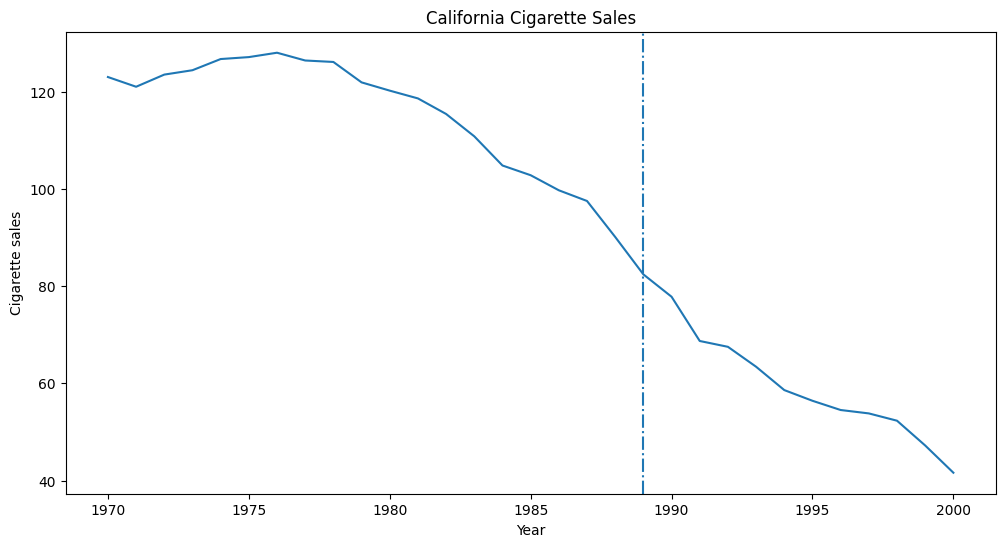

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(CA["year"], CA["cigsale"])

plt.axvline(1989, linestyle="-.")

plt.xlabel("Year")
plt.ylabel("Cigarette sales")
plt.title("California Cigarette Sales")

plt.show()

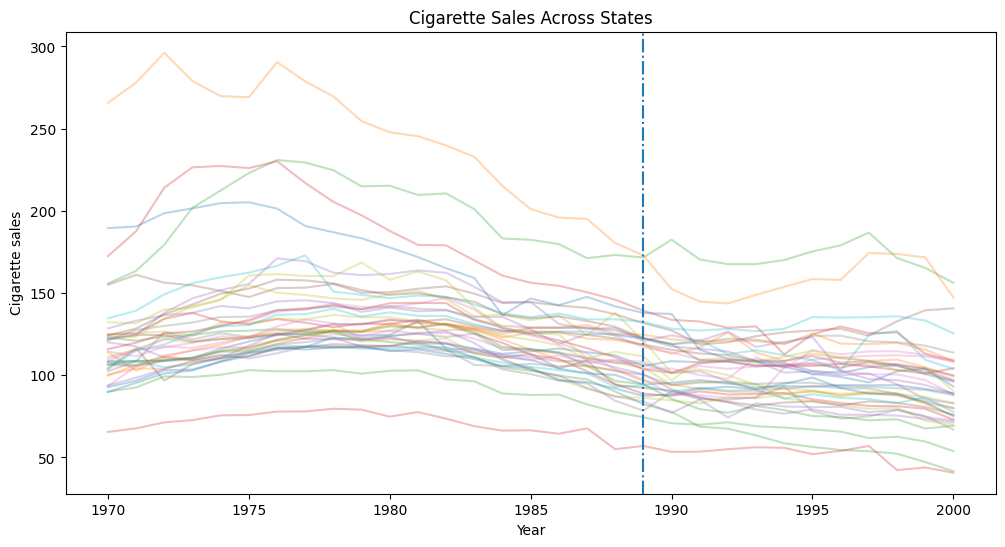

In [12]:
plt.figure(figsize=(12, 6))

for state in df["state"].unique():
    state_data = df[df["state"] == state]
    plt.plot(
        state_data["year"],
        state_data["cigsale"],
        alpha=0.3
    )

plt.axvline(1989, linestyle="-.")

plt.xlabel("Year")
plt.ylabel("Cigarette sales")
plt.title("Cigarette Sales Across States")

plt.show()

In [13]:
pivot = df.pivot(index="year",columns="state",values="cigsale")
treated = pivot["California"]
controls = pivot.drop(columns="California")

In [14]:
pre_years = pivot.index < 1989
Y_pre = treated[pre_years]
X_pre = controls.loc[pre_years]

In [15]:
X = X_pre.values
y = Y_pre.values

def loss(weghts):
    snthetic = X @ weghts
    return np.mean((y - snthetic) ** 2)

def gradient(weghts):
    snthetic = X @ weghts
    return -2 * X.T @ (y - snthetic) / len(y)


In [17]:
constraints = {"type": "eq","fun": lambda w: np.sum(w) - 1}
bounds = [(0, 1) for _ in range(X_pre.shape[1])]

In [18]:
from scipy.optimize import minimize

np.random.seed(42)
n_features = X.shape[1]
initial_weights_list = [np.ones(n_features) / n_features] + [
    np.random.dirichlet(np.ones(n_features)) for _ in range(20)
]

best_result = None
for initial_weights in initial_weights_list:
    result = minimize(
        loss,
        initial_weights,
        jac=gradient,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={
            "maxiter": 5000,
            "ftol": 1e-10
        }
    )

    if result.success and (best_result is None or result.fun < best_result.fun):
        best_result = result

if best_result is not None:
    print("Success:", best_result.success)
    print("Message:", best_result.message)
    print("Loss:", best_result.fun)
else:
    print("Optimizasiya heç bir başlanğıc nöqtəsində uğurlu alınmadı.")

Success: True
Message: Optimization terminated successfully
Loss: 2.7436622859625173


In [24]:
weghts_df = (
    pd.DataFrame({"state": X_pre.columns, "weght": best_result.x})
    .sort_values("weght", ascending=False)
    .head(10)
)

In [25]:
snthetic_ca = controls.dot(weghts)
snthetic_ca.name = "Synthetic California"

snthetic_ca.head()

,Synthetic California
year,
1970,117.424044
1971,119.822989
1972,124.646409
1973,124.367229
1974,126.473692


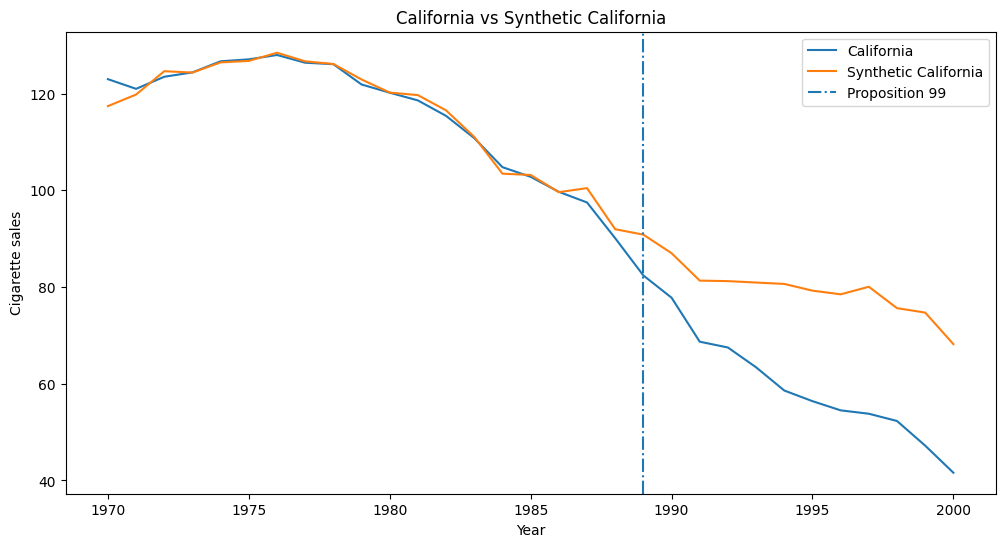

In [27]:
plt.figure(figsize=(12, 6))

plt.plot(treated.index,treated.values,label="California")

plt.plot(snthetic_ca.index,snthetic_ca.values,label="Synthetic California")

plt.axvline(1989,linestyle="-.",label="Proposition 99")

plt.xlabel("Year")
plt.ylabel("Cigarette sales")
plt.title("California vs Synthetic California")
plt.legend()
plt.show()

Nəzarət ştatları üçün ən yaxşı çəkiləri tapmaq məqsədilə 1989-cu ildən əvvəlki məlumatlardan istifadə edirik. Optimizasiya prosesi sintetik Kaliforniyanın real Kaliforniyaya uyğunlaşmasına kömək edən ştatlara daha yüksək çəkilər verir. Yeni sintetik Kaliforniya 1989-cu ildən əvvəlki dövrdə real Kaliforniyaya çox yaxındır. 1988-89-cu ildən sonra isə hər iki xətt bir-birindən fərqlənməyə başlayır ki, bu da bizə mümkün təsirin (müalicə effektinin) qiymətləndirilməsini təmin edir.


In [28]:
pre_actual = treated[treated.index < 1989]
pre_snthetic = snthetic_ca[snthetic_ca.index < 1989]

In [30]:
pre_rmse = np.sqrt(mean_squared_error(pre_actual, pre_snthetic))
print("Pre-treatment RMSE:", pre_rmse)

Pre-treatment RMSE: 1.6564004002542734


In [33]:
pre_mae = mean_absolute_error(pre_actual, pre_snthetic)
print("Pre-treatment MAE:", pre_mae)

Pre-treatment MAE: 1.02479798533323


In [34]:
gap = treated - snthetic_ca

post_treatment_gap = gap[gap.index >= 1989]
post_treatment_gap

,0
year,
1989,-8.440482
1990,-9.206956
1991,-12.634299
1992,-13.728696
1993,-17.533608
1994,-22.049100
1995,-22.857574
1996,-23.997373
1997,-26.260771


In [36]:
att = post_treatment_gap.mean()
print(f"ATT (Average Treatment Effect): {att:.4f}")

ATT (Average Treatment Effect): -19.5136


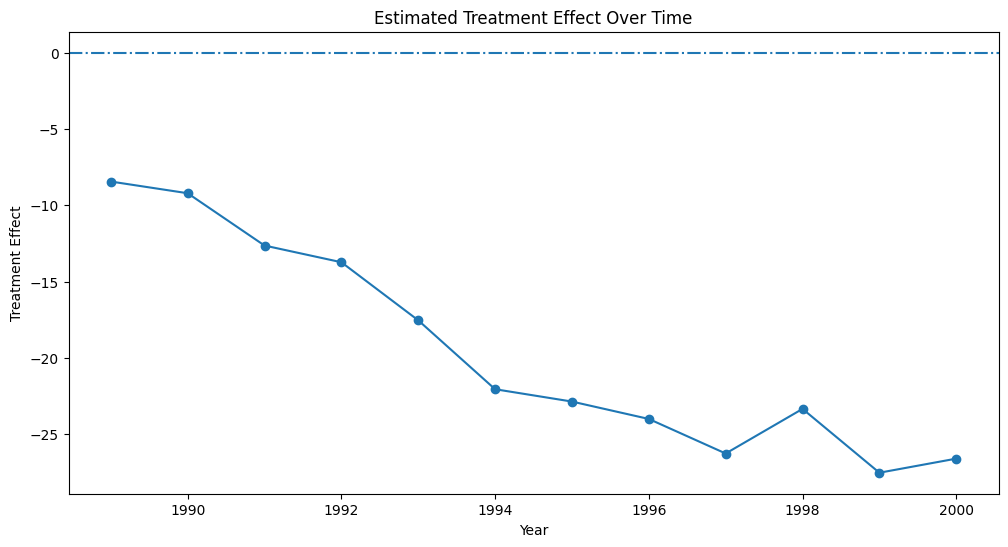

In [38]:
plt.figure(figsize=(12, 6))
plt.plot(post_treatment_gap.index,post_treatment_gap.values,marker="o")
plt.axhline(0, linestyle="-.")
plt.xlabel("Year")
plt.ylabel("Treatment Effect")
plt.title("Estimated Treatment Effect Over Time")

plt.show()

In [39]:
placebo_state = "Nevada"
placebo_treated = pivot[placebo_state]
placebo_controls = pivot.drop(columns=placebo_state)

In [40]:
placebo_pre_years = pivot.index < 1989
placebo_Y_pre = placebo_treated[placebo_pre_years]
placebo_X_pre = placebo_controls.loc[placebo_pre_years]

In [41]:
X_placebo = placebo_X_pre.values
y_placebo = placebo_Y_pre.values

def placebo_loss(weghts):
    return np.mean((y_placebo - X_placebo @ weghts) ** 2)

placebo_constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}

n_placebo_donors = placebo_X_pre.shape[1]
placebo_bounds = [(0, 1)] * n_placebo_donors

In [42]:
np.random.seed(42)
n_placebo_features = placebo_X_pre.shape[1]

placebo_initial_weghts_list = [
    np.ones(n_placebo_features) / n_placebo_features
] + [
    np.random.dirichlet(np.ones(n_placebo_features)) for _ in range(20)
]

best_placebo_result = None

for initial_weights in placebo_initial_weghts_list:
    result = minimize(
        placebo_loss,
        initial_weights,
        method="SLSQP",
        bounds=placebo_bounds,
        constraints=placebo_constraints,
        options={
            "maxiter": 5000,
            "ftol": 1e-10
        }
    )

    if result.success and (
        best_placebo_result is None or result.fun < best_placebo_result.fun
    ):
        best_placebo_result = result

if best_placebo_result is not None:
    print("Success:", best_placebo_result.success)
    print("Message:", best_placebo_result.message)
    print("Loss:", best_placebo_result.fun)
else:
    print("Placebo optimizasiyası heç bir başlanğıc nöqtəsində uğurlu alınmadı.")

Success: True
Message: Optimization terminated successfully
Loss: 40.32257117615992


In [43]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

snthetic_nevada = pd.Series(
    placebo_controls.values @ best_placebo_result.x,
    index=placebo_controls.index,
    name="Snthetic Nevada"
)

is_pre_1989 = placebo_treated.index < 1989
placebo_pre_actual = placebo_treated[is_pre_1989]
placebo_pre_synthetic = snthetic_nevada[is_pre_1989]

placebo_rmse = np.sqrt(mean_squared_error(placebo_pre_actual, placebo_pre_synthetic))
placebo_mae = mean_absolute_error(placebo_pre_actual, placebo_pre_synthetic)

print(f"Placebo Pre-treatment RMSE: {placebo_rmse:.4f}")
print(f"Placebo Pre-treatment MAE: {placebo_mae:.4f}")

Placebo Pre-treatment RMSE: 6.3500
Placebo Pre-treatment MAE: 4.8955


In [44]:
placebo_effect = placebo_treated - snthetic_nevada
placebo_post_effect = placebo_effect[placebo_effect.index >= 1989]
placebo_ATT = placebo_post_effect.mean()

print(f"Placebo ATT (Orta Təsir): {placebo_ATT:.4f}")

Placebo ATT (Orta Təsir): 0.7510


1989-cu ildən sonra baş verən digər amillər də siqaret satışlarına təsir etmiş ola bilər. Bəzi vacib amillər verilənlər bazasına daxil edilməmiş ola bilər. Buna görə də, nəticə Proposition 99-un bütün effekti yaratdığının qüsursuz sübutu deyil. Model Sintetik Kaliforniyanı qurmaq üçün əsasən 1989-cu ildən əvvəlki siqaret satışlarından istifadə etmişdir. Gəlir, pivə istehlakı və pərakəndə satış qiyməti kimi digər proqnozlaşdırıcılar birbaşa istifadə olunmamışdır. Bu proqnozlaşdırıcıların daxil edilməsi alternativ ssenarinin (counterfactual) qurulması üçün daha ətraflı məlumat təmin edə bilərdi.